# Statistics: scaling, composition and homologs
Tests of H1, H2 and H3 in the animals that passed the screening

This notebook only reads the tables in `data/`, so it can be run on its own. It tests the three hypotheses on the animals whose centromeres are resolved well enough to be measured: `IMCG_204112`, the animal of the reference assembly (haplotypes P and M), and a Kiko × Saanen F1 female (haplotypes KikoP and SaanenM), found in the screening of notebook 02.

| Part | What it does |
|---|---|
| A · The reference animal (3.1–3.6) | H1, H2 and H3 in IMCG_204112, with influence, power and sensitivity analyses, and the exploratory comparison between breeds |
| B · The second animal and the comparison (3.7–3.11) | H1 and H3 in the four haplotypes, and how much a centromere changes within an animal and between animals |

Methods in short: log-log (allometric) scaling for H1, pairwise log-ratios for composition (Greenacre et al. 2022) and paired permutation tests for the homologs.

# Part A · The reference animal

## 3.0 · Setup and loading the tables

In [1]:
import os, re, io, gzip, json, subprocess, shlex
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

Q = lambda p: shlex.quote(str(p))
BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
TAB = BASE/'data'; READS = TAB/'reads'; FIG = TAB/'figures'; FIG.mkdir(exist_ok=True)
THREADS = os.cpu_count() or 2; SEED = 20241013; KINDS_SAT = ['SatI', 'SatII', 'SatIII']
MIN_SAT_FRAC = 0.30
sat_lib = TAB/'satellites_SatI-III.fa'

cen    = pd.read_csv(TAB/'centromeres_master.csv')
chroms = pd.read_csv(TAB/'chromosomes.csv')
units  = pd.read_csv(TAB/'srf_units.csv')
runs   = pd.read_csv(TAB/'public_runs.csv')
T = cen[cen.hap == 'T2T']
print(len(cen), 'rows (chromosome × haplotype) |', units.family.value_counts().to_dict(), '|', len(runs), 'PacBio runs')
print('T2T: centromere length (Mb) min %.2f (%s) · max %.2f (%s) · median %.2f' % (
      T.cen_len.min()/1e6, T.loc[T.cen_len.idxmin(), 'chr'], T.cen_len.max()/1e6, T.loc[T.cen_len.idxmax(), 'chr'], T.cen_len.median()/1e6))

89 rows (chromosome × haplotype) | {'SatIII': 7, 'SatI': 7, 'other': 5, 'SatII': 2} | 6 PacBio runs
T2T: centromere length (Mb) min 0.85 (CHIX) · max 10.38 (CHI16) · median 7.14


## 3.1 · H1, scaling of the centromere
How much does the centromere grow when the chromosome grows? The model is `ln(centromere) = a + b · ln(remaining length)`, where the remaining length is the chromosome length minus the centromere. Using it avoids the built-in coupling you get with the fraction. With b = 1 the centromere grows in proportion to the chromosome, with b between 0 and 1 it grows less, and with b = 0 it does not depend on size. The data are the 30 chromosomes of T2T-goat2.0 (29 autosomes and the X).

What is measured is the length of the satellite block, not the functional centromere (the CENP-A domain). The functional size is limited and follows genome or chromosome size across species (Plačková et al. 2021; Wang et al. 2021; Irvine et al. 2004), but within a species it is fairly uniform (Zhang and Dawe 2012). The satellite array has no such limit and varies a lot between chromosomes, haplotypes and individuals, up to 30-fold in humans (Logsdon et al. 2025; Sullivan et al. 2011; Thakur et al. 2021). A strong correlation with chromosome size is therefore not expected. We test it anyway and report the power, to tell "there is no scaling" apart from "we could not have seen it".

What is reported. The main result is the slope and its interval, not the p-value.
- Tests of b = 0 (is there scaling?) and of b = 1 against b < 1. The second is almost trivial when b is close to 0, so it is not the main criterion.
- Intervals from a t distribution with robust errors (HC3) and a percentile bootstrap of chromosomes (5000 resamples).
- Influence: Cook's distance and the slope leaving each chromosome out. The X carries a lot of weight.
- Sensitivity: without the X, with satellite bp as the response, with total length as the predictor, with robust regressions (Theil–Sen, Huber), and repeating the fit in P and M separately (M also without the `low_satellite` blocks).
- Power: which true slope the analysis could detect given the observed scatter, with and without the X.

In [2]:
D = cen[(cen.hap == 'T2T') & cen.complete & cen.cen_len.notna()].copy()
D['cen_Mb'] = D.cen_len/1e6; D['rest_Mb'] = (D.length - D.cen_len)/1e6
D['lcen'], D['lrest'] = np.log(D.cen_Mb), np.log(D.rest_Mb)
D['lsat'], D['lchr'] = np.log(D.sat_bp/1e6), np.log(D.length/1e6)

rng_h1 = np.random.default_rng(SEED)
def h1_row(df, y, x, label, how='ols'):
    df = df.dropna(subset=[y, x]); X, Y, n = df[x].to_numpy(), df[y].to_numpy(), len(df)
    p0 = p1 = r2 = r2a = np.nan
    if how == 'ols':
        m = smf.ols(f'{y} ~ {x}', df).fit(cov_type='HC3'); b, se = m.params[x], m.bse[x]
        lo, hi = m.conf_int().loc[x]; r2, p0, r2a = m.rsquared, m.pvalues[x], m.rsquared_adj
        p1 = stats.t.cdf((b - 1)/se, m.df_resid)              # H0: b = 1 against b < 1
    elif how == 'theil':
        b, _, lo, hi = stats.theilslopes(Y, X, 0.95)
    else:                                                     # Huber
        m = smf.rlm(f'{y} ~ {x}', df, M=sm.robust.norms.HuberT()).fit(); b = m.params[x]; lo, hi = m.conf_int().loc[x]; p0 = m.pvalues[x]
    if how == 'theil': fit = lambda x, y: stats.theilslopes(y, x)[0]                    # the bootstrap uses the same estimator as the row
    elif how == 'huber': fit = lambda x, y: sm.RLM(y, sm.add_constant(x), M=sm.robust.norms.HuberT()).fit().params[1]
    else: fit = lambda x, y: np.polyfit(x, y, 1)[0]
    idx = rng_h1.integers(0, n, (5000, n)); bs = np.array([fit(X[i], Y[i]) for i in idx])
    rho, prho = stats.spearmanr(X, Y)
    return dict(model=label, n=n, slope=b, CI95=f'[{lo:.2f}, {hi:.2f}]', CI95_boot=f'[{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]',
                p_slope_0=p0, p_slope_lt_1=p1, R2=r2, R2_adj=r2a, spearman=rho, p_spearman=prho)

def hap_frame(hap, drop_low=False):
    d = cen[(cen.hap == hap) & cen.complete & cen.cen_len.notna() & (cen.kind != 'Y')].copy()
    if drop_low: d = d[~d.low_satellite]
    d['lcen'] = np.log(d.cen_len/1e6); d['lrest'] = np.log((d.length - d.cen_len)/1e6); return d

rows = [h1_row(D, 'lcen', 'lrest', 'MAIN · T2T, 29 autosomes + X'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'without the X'),
        h1_row(D, 'lsat', 'lrest', 'response = pure satellite (sat_Mb)'),
        h1_row(D, 'lcen', 'lchr', 'predictor = total chromosome length'),
        h1_row(D, 'lcen', 'lrest', 'Theil–Sen (robust), with X', 'theil'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'Theil–Sen (robust), without X', 'theil'),
        h1_row(D, 'lcen', 'lrest', 'Huber (robust), with X', 'huber'),
        h1_row(hap_frame('P'), 'lcen', 'lrest', 'replicate: haplotype P (complete autosomes)'),
        h1_row(hap_frame('M'), 'lcen', 'lrest', 'replicate: haplotype M (complete autosomes + X)'),
        h1_row(hap_frame('M', True), 'lcen', 'lrest', 'replicate: haplotype M without low_satellite blocks')]
h1 = pd.DataFrame(rows)             # the first row is the main result (other cells read it)
h1.to_csv(TAB/'H1_scaling.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
display(h1.round(4))

,model,n,slope,CI95,CI95_boot,p_slope_0,p_slope_lt_1,R2,R2_adj,spearman,p_spearman
0,"MAIN · T2T, 29 autosomes + X",30,-0.1166,"[-0.80, 0.57]","[-0.81, 0.38]",0.7384,0.0017,0.0086,-0.0268,0.0705,0.7111
1,without the X,29,0.1884,"[-0.10, 0.47]","[-0.11, 0.44]",0.1930,0.0000,0.0622,0.0275,0.1734,0.3684
2,response = pure satellite (sat_Mb),30,-0.1176,"[-0.79, 0.55]","[-0.81, 0.37]",0.7301,0.0014,0.0089,-0.0265,0.0585,0.7588
3,predictor = total chromosome length,30,-0.0520,"[-0.75, 0.64]","[-0.80, 0.45]",0.8833,0.0030,0.0015,-0.0342,0.1221,0.5203
4,"Theil–Sen (robust), with X",30,0.0216,"[-0.33, 0.38]","[-0.40, 0.40]",NaN,NaN,NaN,NaN,0.0705,0.7111
5,"Theil–Sen (robust), without X",29,0.1093,"[-0.18, 0.46]","[-0.23, 0.46]",NaN,NaN,NaN,NaN,0.1734,0.3684
6,"Huber (robust), with X",30,0.1086,"[-0.18, 0.40]","[-0.32, 0.42]",0.4671,NaN,NaN,NaN,0.0705,0.7111
7,replicate: haplotype P (complete autosomes),20,0.1943,"[-0.11, 0.50]","[-0.18, 0.46]",0.2065,0.0000,0.0352,-0.0184,0.1579,0.5061
8,replicate: haplotype M (complete autosomes + X),25,0.0136,"[-0.87, 0.90]","[-0.81, 0.79]",0.9761,0.0200,0.0001,-0.0434,0.1754,0.4017
9,replicate: haplotype M without low_satellite blocks,22,-0.0179,"[-0.92, 0.88]","[-0.84, 0.76]",0.9689,0.0191,0.0001,-0.0499,0.2230,0.3184


In [3]:
# Influence: Cook's distance and the slope leaving each chromosome out (main model)
m_main = smf.ols('lcen ~ lrest', D).fit()
D['cook'] = m_main.get_influence().cooks_distance[0]
D['slope_without_this'] = [np.polyfit(D.lrest.drop(i), D.lcen.drop(i), 1)[0] for i in D.index]
threshold = 4/len(D)
infl = D[D.cook > threshold][['chr', 'kind', 'cen_Mb', 'rest_Mb', 'cook', 'slope_without_this']].sort_values('cook', ascending=False)
print(f'Main slope: {m_main.params["lrest"]:.3f}. Leaving one chromosome out at a time: [{D.slope_without_this.min():.3f}, {D.slope_without_this.max():.3f}]')
print(f'Influential chromosomes (Cook > 4/n = {threshold:.3f}):'); display(infl.round(3))
infl.to_csv(TAB/'H1_influence.csv', index=False)

b0 = h1.iloc[0]
print('\nReading:')
print(f'· Slope = {b0.slope:.2f} (CI95 {b0.CI95}; bootstrap {b0.CI95_boot}); R² = {b0.R2:.3f}.')
print(f'· H0 b = 0: p = {b0.p_slope_0:.3g} → ' + ('no evidence of scaling.' if b0.p_slope_0 > 0.05 else 'evidence of scaling.'))
print(f'· H0 b = 1 vs b < 1: p = {b0.p_slope_lt_1:.3g} (expected when b is close to 0; it is not the central criterion).')

# Interaction: does the slope differ between haplotypes P and M?
# The two haplotypes come from the same animal, so errors are cluster-robust by chromosome. (X vs autosomes is not estimable: there is a single X.)
pm = pd.concat([hap_frame('P'), hap_frame('M')]); pm = pm[pm.kind == 'autosome'].copy()
mi = smf.ols('lcen ~ lrest * C(hap)', pm).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(pm.chr)[0]})
term = [t for t in mi.params.index if t.startswith('lrest:')][0]
inter = pd.DataFrame([dict(model='lcen ~ lrest * hap (P vs M, complete autosomes)', n=len(pm), slope_P=mi.params['lrest'],
                           slope_diff_M_minus_P=mi.params[term], CI95_diff=f'[{mi.conf_int().loc[term, 0]:.2f}, {mi.conf_int().loc[term, 1]:.2f}]',
                           p_interaction=mi.pvalues[term], R2_adj=mi.rsquared_adj)])
inter.to_csv(TAB/'H1_interaction.csv', index=False); display(inter.round(4))
print('Reading: ' + ('the slopes of P and M do not differ detectably.' if inter.p_interaction.iloc[0] > 0.05 else 'the slopes of P and M differ.'))

Main slope: -0.117. Leaving one chromosome out at a time: [-0.193, 0.188]
Influential chromosomes (Cook > 4/n = 0.133):


,chr,kind,cen_Mb,rest_Mb,cook,slope_without_this
29,CHIX,X,0.853,143.836,1.192,0.188



Reading:
· Slope = -0.12 (CI95 [-0.80, 0.57]; bootstrap [-0.81, 0.38]); R² = 0.009.
· H0 b = 0: p = 0.738 → no evidence of scaling.
· H0 b = 1 vs b < 1: p = 0.00171 (expected when b is close to 0; it is not the central criterion).


,model,n,slope_P,slope_diff_M_minus_P,CI95_diff,p_interaction,R2_adj
0,"lcen ~ lrest * hap (P vs M, complete autosomes)",44,0.3358,-0.1415,"[-0.74, 0.46]",0.6432,0.0622


Reading: the slopes of P and M do not differ detectably.


In [4]:
# Power of the scaling analysis, using the observed dispersion of the data (two-sided t model, alpha = 0.05)
def power(df, label, betas=(0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0)):
    x, y = df.lrest.to_numpy(), df.lcen.to_numpy(); n = len(df)
    b, a = np.polyfit(x, y, 1); s = (y - a - b*x).std(ddof=2); se = s/(x.std(ddof=1)*np.sqrt(n - 1)); dfree = n - 2; tc = stats.t.ppf(0.975, dfree)
    pw = [dict(model=label, true_slope=bt, power=1 - stats.nct.cdf(tc, dfree, bt/se) + stats.nct.cdf(-tc, dfree, bt/se)) for bt in betas]
    z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
    return pw, dict(model=label, n=n, SD_residual=s, SE_slope=se, min_detectable_slope_80=z*se, min_detectable_correlation_80=np.tanh(z/np.sqrt(n - 3)))

pw1, r1 = power(D, 'with X (29 autosomes + X)'); pw2, r2 = power(D[D.kind == 'autosome'], 'without X (29 autosomes)')
h1_pot = pd.DataFrame(pw1 + pw2); h1_pot_res = pd.DataFrame([r1, r2])
h1_pot.to_csv(TAB/'H1_power.csv', index=False); h1_pot_res.to_csv(TAB/'H1_power_summary.csv', index=False)
display(h1_pot.pivot(index='true_slope', columns='model', values='power').round(2)); display(h1_pot_res.round(3))
ci_noX = h1.CI95.iloc[1]
print(f'Reading: without the X (n = {r2["n"]}) the analysis would detect with 80 % power a slope ≥ {r2["min_detectable_slope_80"]:.2f}; with the X, ≥ {r1["min_detectable_slope_80"]:.2f} (the X doubles the standard error). '
      f'Without the X a strong scaling can be ruled out (slope ≥ 0.5; power without X {h1_pot[(h1_pot.model.str.startswith("without")) & (h1_pot.true_slope == 0.5)].power.iloc[0]:.2f}), but not a weak or moderate one (0.2–0.4). '
      f'Interval of the slope without the X: {ci_noX}. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).')

model,with X (29 autosomes + X),without X (29 autosomes)
true_slope,,
0.10,0.07,0.11
0.20,0.13,0.28
0.30,0.23,0.54
0.40,0.37,0.78
0.50,0.53,0.93
0.75,0.86,1.00
1.00,0.98,1.00


,model,n,SD_residual,SE_slope,min_detectable_slope_80,min_detectable_correlation_80
0,with X (29 autosomes + X),30,0.477,0.236,0.662,0.492
1,without X (29 autosomes),29,0.273,0.141,0.394,0.500


Reading: without the X (n = 29) the analysis would detect with 80 % power a slope ≥ 0.39; with the X, ≥ 0.66 (the X doubles the standard error). Without the X a strong scaling can be ruled out (slope ≥ 0.5; power without X 0.93), but not a weak or moderate one (0.2–0.4). Interval of the slope without the X: [-0.10, 0.47]. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).


## 3.2 · H2, satellite composition
Does composition explain part of the variation in centromere size?

The SatI:SatII:SatIII proportions come from the same block whose length we want to explain, so part of any relationship is mechanical. The main analysis is therefore the allometry by family, `ln(bp of the family)` against `ln(remaining length)`. It shows which family drives the size without using proportions.

For composition we use one pairwise log-ratio, `ln(SatI/SatII)`, instead of two ILR balances with zero replacement. Greenacre et al. 2022 argue that pairwise ratios are a valid alternative. SatIII is missing from several chromosomes, so it stays out of the ratio and is assessed as presence or absence.

The tests are a nested F test (`lcen ~ lrest` against `lcen ~ lrest + ln(SatI/SatII)`), the partial R², AIC and the coefficient with HC3 errors. For robustness we repeat it without the X, leave each chromosome out in turn and bootstrap the gain in R².

In [5]:
for k in KINDS_SAT: D['p_' + k] = D[k] / D.sat_bp                     # proportions (descriptive; used by the figure)
ok_ratio = (D.SatI > 0) & (D.SatII > 0)
D['lr_I_II'] = np.where(ok_ratio, np.log(D.SatI.clip(lower=1) / D.SatII.clip(lower=1)), np.nan)   # pairwise log-ratio
D['has_III'] = (D.SatIII > 0).astype(int)
D['other_Mb'] = (D.cen_len - D.sat_bp)/1e6                             # non-satellite sequence inside the block
print('Chromosomes with SatI and SatII > 0:', int(ok_ratio.sum()), 'of', len(D), '| with SatIII:', int(D.has_III.sum()), '| without SatIII:', D.loc[D.has_III == 0, 'chr'].tolist())

# (a) Allometry by family — main result of H2
fam_rows = []
for k in KINDS_SAT:
    d = D[D[k] > 0].assign(ly=lambda x: np.log(x[k]/1e6)); fam_rows.append(h1_row(d, 'ly', 'lrest', f'{k} (bp in the block)'))
fam_rows.append(h1_row(D.assign(ly=np.log(D.sat_bp/1e6)), 'ly', 'lrest', 'total satellite (SatI–III)'))
d = D[D.other_Mb > 0].assign(ly=lambda x: np.log(x.other_Mb)); fam_rows.append(h1_row(d, 'ly', 'lrest', 'non-satellite inside the block'))
h2_fam = pd.DataFrame(fam_rows); h2_fam.to_csv(TAB/'H2_family_allometry.csv', index=False)
print('Allometry by family (slope of ln(bp) against ln(remaining length)):'); display(h2_fam[['model', 'n', 'slope', 'CI95', 'CI95_boot', 'p_slope_0', 'R2_adj', 'spearman']].round(4))

Chromosomes with SatI and SatII > 0: 30 of 30 | with SatIII: 24 | without SatIII: ['CHI4', 'CHI12', 'CHI16', 'CHI22', 'CHI28', 'CHIX']


Allometry by family (slope of ln(bp) against ln(remaining length)):


,model,n,slope,CI95,CI95_boot,p_slope_0,R2_adj,spearman
0,SatI (bp in the block),30,-0.3704,"[-1.71, 0.97]","[-1.73, 0.56]",0.5892,-0.0107,0.0736
1,SatII (bp in the block),30,0.0868,"[-0.20, 0.37]","[-0.17, 0.38]",0.5488,-0.0212,0.0834
2,SatIII (bp in the block),24,0.8256,"[-1.36, 3.01]","[-1.40, 2.65]",0.4592,-0.0132,0.1800
3,total satellite (SatI–III),30,-0.1176,"[-0.79, 0.55]","[-0.77, 0.36]",0.7301,-0.0265,0.0585
4,non-satellite inside the block,30,-0.1132,"[-0.89, 0.67]","[-0.90, 0.52]",0.7763,-0.0307,0.0283


In [6]:
# (b) Does the H1 model improve when the SatI/SatII ratio is added?
rng_h2 = np.random.default_rng(SEED)
def comp_row(df, label, extra=''):
    df = df.dropna(subset=['lr_I_II']); n = len(df)
    m0 = smf.ols('lcen ~ lrest', df).fit(); m1 = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit()
    f, p, _ = m1.compare_f_test(m0)
    mh = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit(cov_type='HC3'); ci = mh.conf_int().loc['lr_I_II']
    cols = ['lrest', 'lr_I_II'] + (['has_III'] if extra else [])
    y = df.lcen.to_numpy(); X0 = np.column_stack([np.ones(n), df.lrest]); X1 = np.column_stack([np.ones(n)] + [df[c] for c in cols])
    def r2(X, yy):
        res = yy - X @ np.linalg.lstsq(X, yy, rcond=None)[0]; return 1 - res @ res / ((yy - yy.mean()) @ (yy - yy.mean()))
    dR = [r2(X1[i], y[i]) - r2(X0[i], y[i]) for i in rng_h2.integers(0, n, (3000, n))]
    return dict(model=label, n=n, R2_base=m0.rsquared, R2_with_composition=m1.rsquared, delta_R2=m1.rsquared - m0.rsquared,
                CI95_boot_delta_R2=f'[{np.percentile(dR, 2.5):.2f}, {np.percentile(dR, 97.5):.2f}]',
                R2_partial=(m1.rsquared - m0.rsquared)/(1 - m0.rsquared), AIC_base=m0.aic, AIC_comp=m1.aic, F=f, p_F=p,
                coef_lr_I_II=mh.params['lr_I_II'], CI95_coef=f'[{ci[0]:.2f}, {ci[1]:.2f}]', p_coef_HC3=mh.pvalues['lr_I_II'])

rows = [comp_row(D, 'MAIN · T2T, 29 autosomes + X'),
        comp_row(D[D.kind == 'autosome'], 'without the X'),
        comp_row(D, 'adding SatIII presence', ' + has_III')]
h2 = pd.DataFrame(rows)                    # the first row is the main one (other cells read it)
h2['p_F_txt'] = h2.p_F.map(lambda p: '< 1e-4' if p < 1e-4 else f'{p:.4f}')
h2.to_csv(TAB/'H2_composition.csv', index=False)
display(h2.drop(columns=['p_F', 'p_coef_HC3']).round(4))

# Influence: coefficient of the ratio leaving one chromosome out at a time
coefs = []
for i in D.dropna(subset=['lr_I_II']).index:
    s = D.drop(i).dropna(subset=['lr_I_II']); coefs.append((D.loc[i, 'chr'], smf.ols('lcen ~ lrest + lr_I_II', s).fit().params['lr_I_II']))
cf = pd.DataFrame(coefs, columns=['chr_dropped', 'coef_lr']).sort_values('coef_lr')
cf.to_csv(TAB/'H2_influence.csv', index=False)
print(f'Coefficient of ln(SatI/SatII) leaving one chromosome out: [{cf.coef_lr.min():.3f}, {cf.coef_lr.max():.3f}] (main: {h2.coef_lr_I_II.iloc[0]:.3f})')
r0 = h2.iloc[0]
print(f'Reading: adding the SatI/SatII ratio raises R² by {r0.delta_R2:.2f} (CI95 boot {r0.CI95_boot_delta_R2}; F p {r0.p_F_txt}). '
      f'Without the X: {h2.delta_R2.iloc[1]:.2f}. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.')
D.to_csv(TAB/'H1H2_chromosome_table_T2T.csv', index=False)

,model,n,R2_base,R2_with_composition,delta_R2,CI95_boot_delta_R2,R2_partial,AIC_base,AIC_comp,F,coef_lr_I_II,CI95_coef,p_F_txt
0,"MAIN · T2T, 29 autosomes + X",30,0.0086,0.7414,0.7327,"[0.05, 0.88]",0.7391,42.6534,4.3429,76.4949,0.4842,"[0.15, 0.81]",< 1e-4
1,without the X,29,0.0622,0.3156,0.2534,"[0.02, 0.63]",0.2702,8.8212,1.6858,9.6272,0.3187,"[0.12, 0.52]",0.0046
2,adding SatIII presence,30,0.0086,0.7422,0.7335,"[0.09, 0.87]",0.7399,42.6534,6.2504,36.9848,0.4887,"[0.13, 0.85]",< 1e-4


Coefficient of ln(SatI/SatII) leaving one chromosome out: [0.319, 0.499] (main: 0.484)
Reading: adding the SatI/SatII ratio raises R² by 0.73 (CI95 boot [0.05, 0.88]; F p < 1e-4). Without the X: 0.25. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.


## 3.3 · H3, variation between homologs (P against M)
Do the two homologs differ more in the centromere than in the rest of the chromosome? We use the autosomes with a complete centromere in both haplotypes. P and M stand in for the two homologs of the reference animal.

Scale is a problem here. A difference of 0.5 Mb is 10 % of a 5-Mb centromere but 0.4 % of the rest of a 130-Mb chromosome. Comparing only relative differences favours the centromere because of the size of the segment, not because of biology. So we compare on two scales: relative, `|ln(P/M)|`, and absolute, `|P − M|` in Mb. The absolute one is closer to what insertions, deletions and array expansions produce.

The tests are a paired Wilcoxon signed-rank test and an exact permutation test (sign flips within each pair), both one-sided (centromere greater than rest), with the median difference and its bootstrap interval.

Sensitivity analyses: without outlier chromosomes (robust z by MAD above 3.5); with a strict criterion (no gap in the whole proximal window of either haplotype); and without the blocks flagged `low_satellite` in either haplotype. The last one runs next to the main analysis, it does not replace it. The difference is also broken down by satellite family.

In [7]:
gaps_all = pd.read_csv(TAB/'proximal_gaps.csv')
P = cen[(cen.hap == 'P') & (cen.kind == 'autosome')].set_index('chr'); M = cen[(cen.hap == 'M') & (cen.kind == 'autosome')].set_index('chr')
keep = ['length', 'cen_len', 'complete', 'n_gaps_cen', 'SatI', 'SatII', 'SatIII', 'low_satellite']
H = P[keep].join(M[keep], lsuffix='_P', rsuffix='_M').dropna()
print(f'Autosomes with both haplotypes: {len(H)}; with a complete centromere in both: {int((H.complete_P & H.complete_M).sum())}')
H = H[H.complete_P & H.complete_M].copy()
H['rest_P'] = H.length_P - H.cen_len_P; H['rest_M'] = H.length_M - H.cen_len_M
H['d_cen']  = np.log(H.cen_len_P / H.cen_len_M); H['d_rest'] = np.log(H.rest_P / H.rest_M)       # relative
H['dabs_cen_Mb']  = (H.cen_len_P - H.cen_len_M)/1e6; H['dabs_rest_Mb'] = (H.rest_P - H.rest_M)/1e6   # absolute
mad = lambda x: 1.4826*np.median(np.abs(x - np.median(x)))
H['robust_z'] = (H.d_cen - H.d_cen.median())/mad(H.d_cen)
H['outlier'] = H.robust_z.abs() > 3.5
H['low_sat'] = H.low_satellite_P | H.low_satellite_M          # low_satellite in either haplotype
g_any = gaps_all.groupby(['hap', 'chr']).size()
H['window_gaps_P'] = [int(g_any.get(('P', c), 0)) for c in H.index]; H['window_gaps_M'] = [int(g_any.get(('M', c), 0)) for c in H.index]
H['strict'] = (H.window_gaps_P == 0) & (H.window_gaps_M == 0)
H.to_csv(TAB/'H3_homologs.csv')
print('\nOutlier chromosomes (the centromere difference departs from the rest):')
display(H[H.outlier][['cen_len_P', 'cen_len_M', 'd_cen', 'robust_z', 'n_gaps_cen_P', 'n_gaps_cen_M', 'window_gaps_P', 'window_gaps_M']].round(2))

rng_h3 = np.random.default_rng(SEED)
def paired_row(df, a, b, label):
    a, b = df[a].abs().to_numpy(), df[b].abs().to_numpy(); n = len(a); dif = a - b
    w = stats.wilcoxon(a, b, alternative='greater')
    pm = stats.permutation_test((a, b), lambda x, y, axis: np.mean(x - y, axis=axis), permutation_type='samples',
                                alternative='greater', n_resamples=np.inf if n <= 18 else 200_000, vectorized=True, random_state=SEED)
    bs = np.median(dif[rng_h3.integers(0, n, (5000, n))], axis=1)
    return dict(comparison=label, n=n, median_centromere=np.median(a), median_rest=np.median(b), median_difference=np.median(dif),
                CI95_median_diff=f'[{np.percentile(bs, 2.5):.3g}, {np.percentile(bs, 97.5):.3g}]', p_wilcoxon=w.pvalue, p_permutation=pm.pvalue), w

r_rel, w = paired_row(H, 'd_cen', 'd_rest', 'relative |ln(P/M)| — all')            # `w` is used by the summary
rows = [r_rel,
        paired_row(H, 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute |P−M| (Mb) — all')[0],
        paired_row(H[~H.outlier], 'd_cen', 'd_rest', 'relative — without outliers')[0],
        paired_row(H[~H.outlier], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — without outliers')[0]]
if H.strict.sum() >= 6:
    rows += [paired_row(H[H.strict], 'd_cen', 'd_rest', 'relative — strict criterion (no gaps in the window)')[0],
             paired_row(H[H.strict], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — strict criterion')[0]]
if (~H.low_sat).sum() >= 6:
    rows += [paired_row(H[~H.low_sat], 'd_cen', 'd_rest', 'relative — without low-satellite blocks')[0],
             paired_row(H[~H.low_sat], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — without low-satellite blocks')[0]]
h3_sens = pd.DataFrame(rows); h3_sens.to_csv(TAB/'H3_sensitivity.csv', index=False)
display(h3_sens.round(4))

# Main summary (columns read by other cells) + breakdown by satellite family
h3 = pd.DataFrame([dict(n_chromosomes=len(H), median_abs_diff_centromere=H.d_cen.abs().median(), median_abs_diff_rest=H.d_rest.abs().median(),
                        SD_diff_centromere=H.d_cen.std(), SD_diff_rest=H.d_rest.std(), p_wilcoxon_centromere_greater=w.pvalue,
                        median_abs_diff_centromere_Mb=H.dabs_cen_Mb.abs().median(), median_abs_diff_rest_Mb=H.dabs_rest_Mb.abs().median(),
                        p_permutation_absolute=h3_sens.p_permutation.iloc[1])])
h3.to_csv(TAB/'H3_summary.csv', index=False)
fam = pd.DataFrame({k: ((H[k + '_P'] - H[k + '_M']).abs()/1e6) for k in KINDS_SAT}).median().rename('median |P−M| (Mb)')
print('\nMedian difference between haplotypes by satellite family (Mb):'); display(fam.round(3).to_frame())
print('Reading: the difference is', 'larger in the centromere on both scales.' if (h3_sens.p_permutation.iloc[:2] < 0.05).all() else 'scale-dependent; review.',
      f'Absolute median: centromere {h3.median_abs_diff_centromere_Mb.iloc[0]:.2f} Mb vs rest {h3.median_abs_diff_rest_Mb.iloc[0]:.2f} Mb.')

Autosomes with both haplotypes: 29; with a complete centromere in both: 18

Outlier chromosomes (the centromere difference departs from the rest):


,cen_len_P,cen_len_M,d_cen,robust_z,n_gaps_cen_P,n_gaps_cen_M,window_gaps_P,window_gaps_M
chr,,,,,,,,
CHI21,9786500,799400,2.5,5.7,0,0,0,0


,comparison,n,median_centromere,median_rest,median_difference,CI95_median_diff,p_wilcoxon,p_permutation
0,relative |ln(P/M)| — all,18,0.3709,0.0012,0.3697,"[0.14, 0.653]",0.0000,0.0000
1,absolute |P−M| (Mb) — all,18,2.6712,0.1069,2.6157,"[1.05, 3.85]",0.0001,0.0001
2,relative — without outliers,17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
3,absolute (Mb) — without outliers,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001
4,relative — strict criterion (no gaps in the window),17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
5,absolute (Mb) — strict criterion,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001
6,relative — without low-satellite blocks,16,0.3709,0.0012,0.3697,"[0.147, 0.628]",0.0000,0.0000
7,absolute (Mb) — without low-satellite blocks,16,2.6712,0.1069,2.6157,"[1.05, 3.57]",0.0000,0.0000



Median difference between haplotypes by satellite family (Mb):


,median |P−M| (Mb)
SatI,1.846
SatII,0.226
SatIII,0.141


Reading: the difference is larger in the centromere on both scales. Absolute median: centromere 2.67 Mb vs rest 0.11 Mb.


## 3.4 · Variation between individuals (secondary and exploratory)
The subsampled reads are mapped to the SatI and SatII units. For each animal we estimate the fraction of bases in each family and `ln(SatI/SatII)`.

The uncertainty comes from a bootstrap over reads (1000 resamples of whole reads). Each breed is compared with the reference animal `IMCG_204112` through the difference in `ln(SatI/SatII)` and its interval. For every run we also report the number of reads, the mean length, the N50 and the fraction of reads with satellite, so that a technical difference is not read as biology.

Limits: the reads are noisy CLR subreads; coverage is about 0.17x and the reads come from the start of each file, so resampling reads does not capture biases of the sequencing cell; the result is a genome-wide fraction, not one per chromosome; and SatIII is not estimated. For `IMCG_204112` the reads give a higher SatI/SatII ratio than the assembly, an offset of about +0.43 that probably comes from mapping differences between the families. Breeds are therefore compared with each other, relative to `IMCG_204112`, and not against the assembly.

In [8]:
def read_lengths(fq):
    names, lens = [], []
    with gzip.open(fq, 'rt') as f:
        for i, line in enumerate(f):
            k = i % 4
            if k == 0: names.append(line[1:].split()[0])
            elif k == 1: lens.append(len(line.strip()))
    return pd.Series(lens, index=names)

NB_BOOT = 1000
rng_r = np.random.default_rng(SEED)
run2ind = runs.set_index('run_accession').individual.to_dict()
ind_rows, boot = [], {}
for fq in sorted(READS.glob('*.subreads.fastq.gz')):
    run = fq.name.split('_')[0]; ind = run2ind.get(run, run)
    rl = read_lengths(fq)
    paf = subprocess.check_output(f"minimap2 -x map-pb -t {THREADS} --secondary=no {Q(sat_lib)} {Q(fq)} 2>/dev/null", shell=True, text=True)
    df = pd.read_csv(io.StringIO(paf), sep='\t', header=None, usecols=[0, 2, 3, 5], names=['q', 'qs', 'qe', 't'])
    df['family'] = df.t.str.split('|').str[0]; df['span'] = df.qe - df.qs
    per = df.groupby(['q', 'family']).span.sum().unstack(fill_value=0).reindex(rl.index, fill_value=0)
    for c in ('SatI', 'SatII'):
        if c not in per: per[c] = 0
    L, sI, sII = rl.to_numpy(float), per.SatI.to_numpy(float), per.SatII.to_numpy(float); n = len(L)
    ln_hat = np.log(sI.sum()/sII.sum())
    bs = np.empty((NB_BOOT, 3))
    for b in range(NB_BOOT):
        i = rng_r.integers(0, n, n); bs[b] = (sI[i].sum()/L[i].sum(), sII[i].sum()/L[i].sum(), np.log(sI[i].sum()/sII[i].sum()))
    boot[ind] = bs[:, 2]
    srt = np.sort(L)[::-1]; n50 = srt[np.searchsorted(np.cumsum(srt), srt.sum()/2)]
    ind_rows.append(dict(run=run, individual=ind, Gb=L.sum()/1e9, n_reads=n, mean_length=L.mean(), N50=n50, frac_reads_with_satellite=float(((sI + sII) > 0).mean()),
                         frac_SatI=sI.sum()/L.sum(), CI95_frac_SatI=f'[{np.percentile(bs[:, 0], 2.5):.4f}, {np.percentile(bs[:, 0], 97.5):.4f}]',
                         frac_SatII=sII.sum()/L.sum(), CI95_frac_SatII=f'[{np.percentile(bs[:, 1], 2.5):.4f}, {np.percentile(bs[:, 1], 97.5):.4f}]',
                         ln_SatI_SatII=ln_hat, CI95_ln=f'[{np.percentile(bs[:, 2], 2.5):.2f}, {np.percentile(bs[:, 2], 97.5):.2f}]'))
ind = pd.DataFrame(ind_rows)
if len(ind):
    ref_ratio = np.log(T.SatI.sum()/T.SatII.sum())
    ind['diff_vs_assembly_ln'] = ind.ln_SatI_SatII - ref_ratio
    if 'IMCG_204112' in boot:
        ref = boot['IMCG_204112']; rr = ind.set_index('individual').ln_SatI_SatII['IMCG_204112']
        d = {k: v - ref for k, v in boot.items()}
        ind['diff_vs_IMCG_ln'] = ind.individual.map(lambda k: ind.set_index('individual').ln_SatI_SatII[k] - rr)
        ind['CI95_diff_vs_IMCG'] = ind.individual.map(lambda k: f'[{np.percentile(d[k], 2.5):.2f}, {np.percentile(d[k], 97.5):.2f}]' if k != 'IMCG_204112' else '—')
    ind.to_csv(TAB/'breeds_pacbio.csv', index=False)
    display(ind[['individual', 'Gb', 'n_reads', 'mean_length', 'N50', 'frac_reads_with_satellite', 'ln_SatI_SatII', 'CI95_ln', 'diff_vs_IMCG_ln', 'CI95_diff_vs_IMCG']].round(3))
    print('ln(SatI/SatII) in the assembly (T2T centromeres):', round(ref_ratio, 3), '· IMCG_204112 in reads:', round(rr, 3), '(calibration: difference', round(rr - ref_ratio, 2), ')')

,individual,Gb,n_reads,mean_length,N50,frac_reads_with_satellite,ln_SatI_SatII,CI95_ln,diff_vs_IMCG_ln,CI95_diff_vs_IMCG
0,Liaoning cashmere goat,0.5,36517,13692.532,13743.0,0.065,2.014,"[1.90, 2.14]",0.092,"[-0.08, 0.27]"
1,Jining gray goat,0.5,29368,17026.314,17505.0,0.048,1.818,"[1.67, 1.98]",-0.104,"[-0.30, 0.10]"
2,Boer goat,0.5,48872,10230.822,10402.0,0.052,1.660,"[1.56, 1.77]",-0.262,"[-0.43, -0.09]"
3,Tibetan goat,0.5,31277,15986.971,23815.0,0.125,0.799,"[0.66, 0.95]",-1.123,"[-1.32, -0.92]"
4,Zhongwei goat,0.5,39738,12582.624,12767.0,0.065,1.826,"[1.72, 1.94]",-0.096,"[-0.27, 0.08]"
5,IMCG_204112,0.5,27692,18056.157,18903.0,0.067,1.922,"[1.79, 2.06]",0.000,—


ln(SatI/SatII) in the assembly (T2T centromeres): 1.493 · IMCG_204112 in reads: 1.922 (calibration: difference 0.43 )


## 3.5 · Figures
The first figure summarises H1–H3. The ones after it come from the same tables and show the data behind the tests.

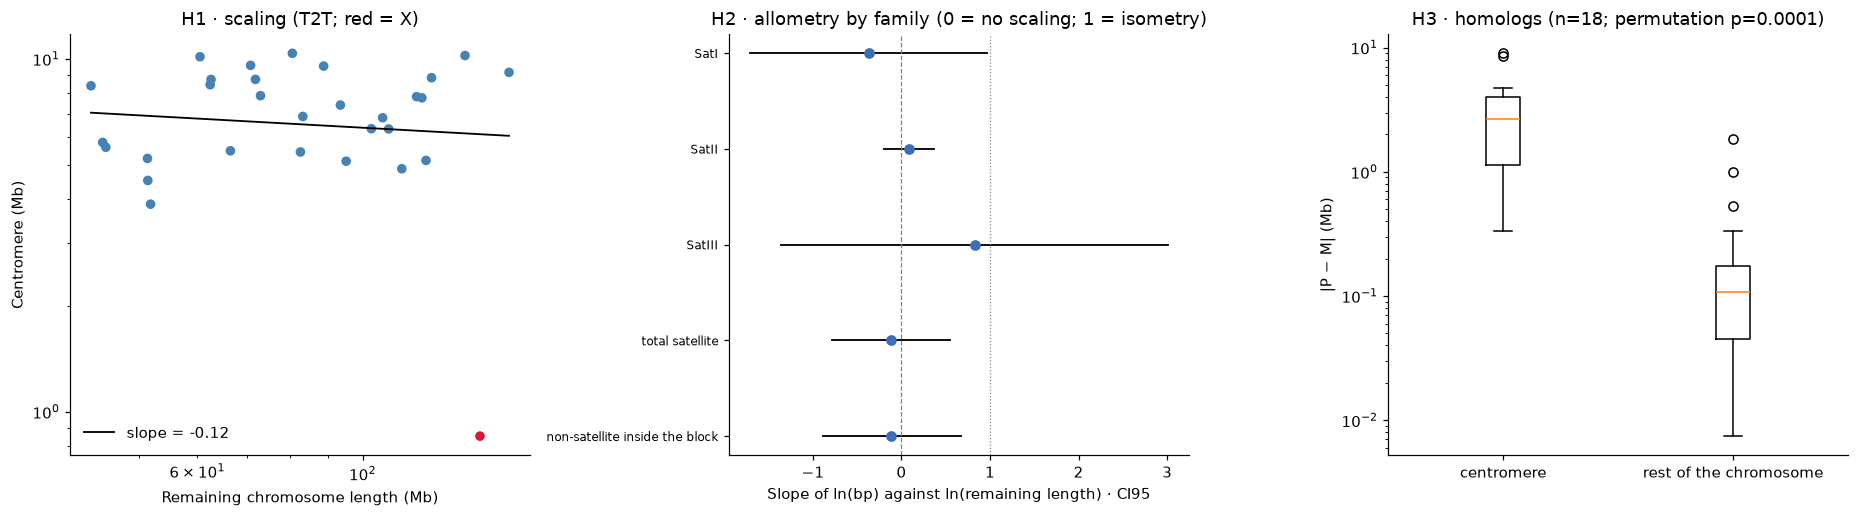

In [9]:
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
nums = lambda s: np.array(re.findall(r'-?\d+\.?\d*', s), float)

# (a) H1
a = ax[0]; a.scatter(D.rest_Mb, D.cen_Mb, c=np.where(D.kind == 'X', 'crimson', 'steelblue'), s=28)
xs = np.linspace(D.lrest.min(), D.lrest.max(), 50); pb = np.polyfit(D.lrest, D.lcen, 1)
a.plot(np.exp(xs), np.exp(np.polyval(pb, xs)), 'k-', lw=1.2, label=f'slope = {pb[0]:.2f}')
a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('Remaining chromosome length (Mb)'); a.set_ylabel('Centromere (Mb)')
a.set_title('H1 · scaling (T2T; red = X)'); a.legend(frameon=False)

# (b) H2: allometry by family (slope and CI95)
b = ax[1]; yy = np.arange(len(h2_fam))[::-1]
for y_, r in zip(yy, h2_fam.itertuples()):
    lo, hi = nums(r.CI95); b.plot([lo, hi], [y_, y_], 'k-', lw=1.2); b.plot(r.slope, y_, 'o', color='#3b6fb6')
b.axvline(0, color='gray', ls='--', lw=.8); b.axvline(1, color='gray', ls=':', lw=.8)
b.set_yticks(yy); b.set_yticklabels([m.split(' (')[0] for m in h2_fam.model], fontsize=8); b.set_xlabel('Slope of ln(bp) against ln(remaining length) · CI95')
b.set_title('H2 · allometry by family (0 = no scaling; 1 = isometry)')

# (c) H3 on the absolute scale
c = ax[2]; c.boxplot([H.dabs_cen_Mb.abs(), H.dabs_rest_Mb.abs()], showfliers=True); c.set_xticklabels(['centromere', 'rest of the chromosome']); c.set_yscale('log')
c.set_ylabel('|P − M| (Mb)'); c.set_title(f'H3 · homologs (n={len(H)}; permutation p={h3_sens.p_permutation.iloc[1]:.4f})')
plt.tight_layout(); plt.savefig(FIG/'summary.png', dpi=150); plt.show()

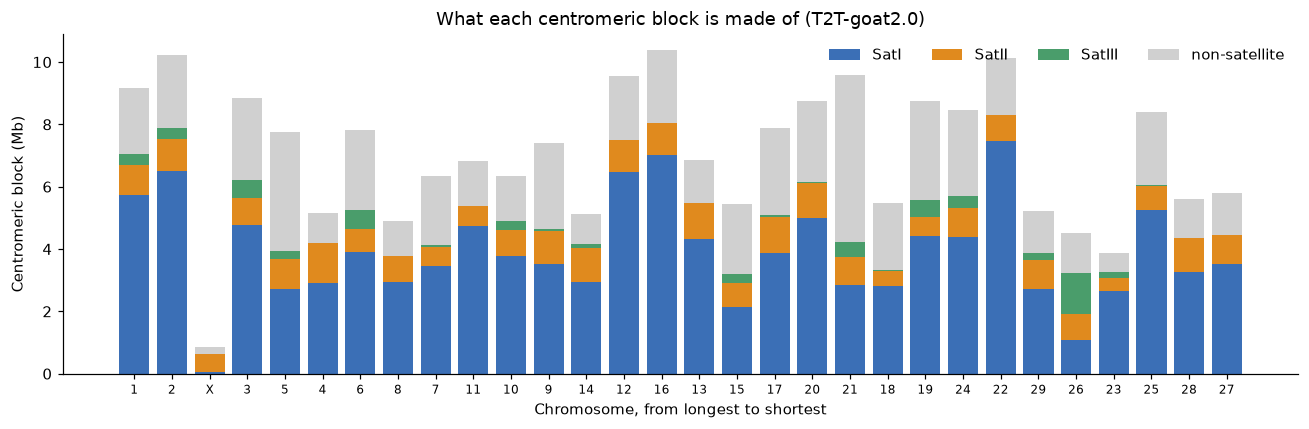

In [10]:
cols = {'SatI': '#3b6fb6', 'SatII': '#e08a1e', 'SatIII': '#4a9d6b'}
t = T[T.cen_len.notna()].sort_values('length', ascending=False)
fig, ax = plt.subplots(figsize=(12, 4)); x = np.arange(len(t)); bot = np.zeros(len(t))
for k in KINDS_SAT:
    v = t[k].to_numpy()/1e6; ax.bar(x, v, bottom=bot, color=cols[k], label=k, width=.8); bot += v
ax.bar(x, (t.cen_len.to_numpy() - t.sat_bp.to_numpy())/1e6, bottom=bot, color='#d0d0d0', label='non-satellite', width=.8)
ax.set_xticks(x); ax.set_xticklabels(t.chr.str.replace('CHI', ''), fontsize=8)
ax.set_xlabel('Chromosome, from longest to shortest'); ax.set_ylabel('Centromeric block (Mb)'); ax.legend(frameon=False, ncol=4)
ax.set_title('What each centromeric block is made of (T2T-goat2.0)')
plt.tight_layout(); plt.savefig(FIG/'composition_by_chromosome.png', dpi=150); plt.show()

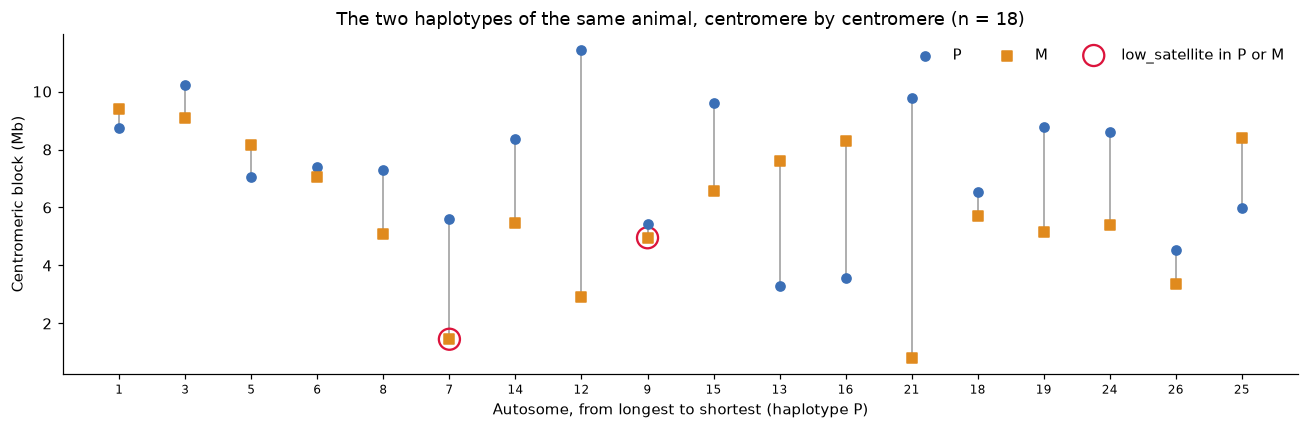

In [11]:
h = H.sort_values('length_P', ascending=False); x = np.arange(len(h))
fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(x, h.cen_len_P/1e6, h.cen_len_M/1e6, color='#999', lw=1)
ax.scatter(x, h.cen_len_P/1e6, color='#3b6fb6', s=36, label='P', zorder=3); ax.scatter(x, h.cen_len_M/1e6, color='#e08a1e', marker='s', s=36, label='M', zorder=3)
lo = h.low_sat.to_numpy()
ax.scatter(x[lo], (h.cen_len_M/1e6).to_numpy()[lo], facecolors='none', edgecolors='crimson', s=190, lw=1.5, label='low_satellite in P or M', zorder=2)
ax.set_xticks(x); ax.set_xticklabels(h.index.str.replace('CHI', ''), fontsize=8); ax.set_xlabel('Autosome, from longest to shortest (haplotype P)')
ax.set_ylabel('Centromeric block (Mb)'); ax.legend(frameon=False, ncol=3); ax.set_title(f'The two haplotypes of the same animal, centromere by centromere (n = {len(h)})')
plt.tight_layout(); plt.savefig(FIG/'haplotypes_by_chromosome.png', dpi=150); plt.show()

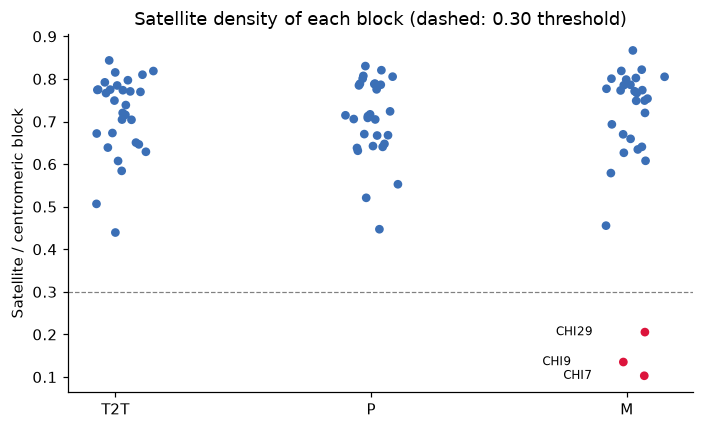

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4)); rng = np.random.default_rng(SEED)
for i, hp in enumerate(['T2T', 'P', 'M']):
    d = cen[(cen.hap == hp) & cen.sat_frac.notna()]
    xj = i + rng.normal(0, .06, len(d)); ax.scatter(xj, d.sat_frac, s=22, color=np.where(d.low_satellite, 'crimson', '#3b6fb6'))
    for xx, r in zip(xj, d.itertuples()):
        if r.low_satellite: ax.annotate('CHI' + r.chr.replace('CHI', ''), (xx, r.sat_frac), xytext=(-34, 0), textcoords='offset points', fontsize=8, va='center', ha='right')
ax.axhline(MIN_SAT_FRAC, color='gray', ls='--', lw=.8); ax.set_xticks(range(3)); ax.set_xticklabels(['T2T', 'P', 'M'])
ax.set_ylabel('Satellite / centromeric block'); ax.set_title('Satellite density of each block (dashed: 0.30 threshold)')
plt.tight_layout(); plt.savefig(FIG/'satellite_density_by_block.png', dpi=150); plt.show()

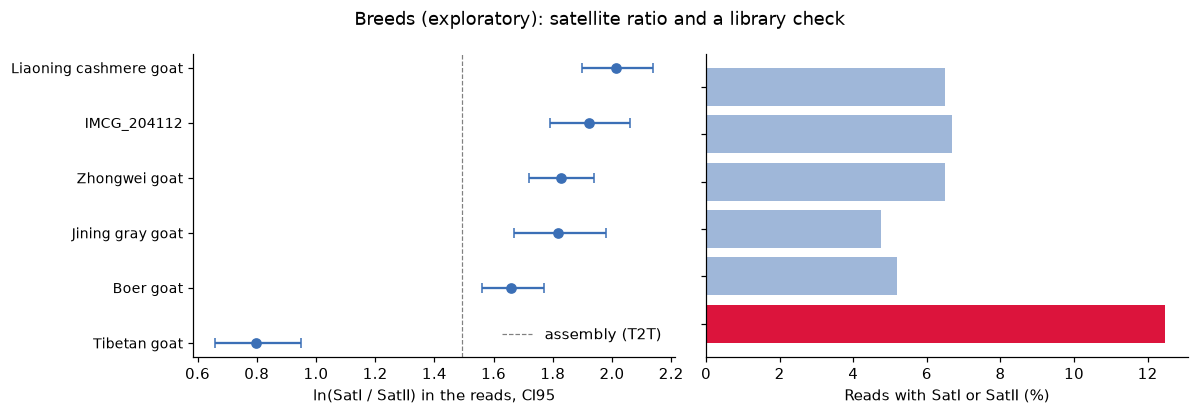

In [13]:
bp_ = TAB/'breeds_pacbio.csv'
if bp_.exists():
    br = pd.read_csv(bp_).sort_values('ln_SatI_SatII')
    ci = np.array([nums(s) for s in br.CI95_ln]); y = np.arange(len(br))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].errorbar(br.ln_SatI_SatII, y, xerr=[br.ln_SatI_SatII - ci[:, 0], ci[:, 1] - br.ln_SatI_SatII], fmt='o', color='#3b6fb6', capsize=3)
    ax[0].axvline(np.log(T.SatI.sum()/T.SatII.sum()), color='gray', ls='--', lw=.8, label='assembly (T2T)')
    ax[0].set_yticks(y); ax[0].set_yticklabels(br.individual, fontsize=9); ax[0].set_xlabel('ln(SatI / SatII) in the reads, CI95'); ax[0].legend(frameon=False, loc='lower right')
    ax[1].barh(y, br.frac_reads_with_satellite*100, color=np.where(br.individual.str.contains('Tibetan'), 'crimson', '#9fb7d9'))
    ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].set_xlabel('Reads with SatI or SatII (%)')
    plt.suptitle('Breeds (exploratory): satellite ratio and a library check'); plt.tight_layout(); plt.savefig(FIG/'breeds.png', dpi=150); plt.show()

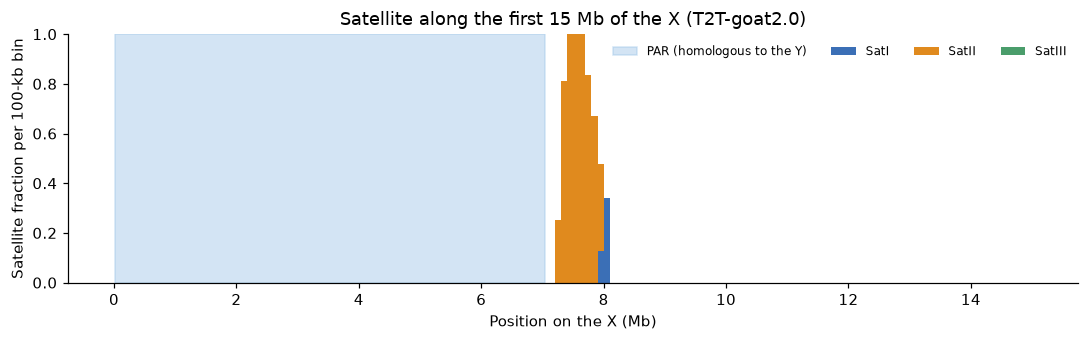

In [14]:
ax_ = pd.read_csv(TAB/'satellite_annotation.csv'); ax_ = ax_[(ax_.hap == 'T2T') & (ax_.chr == 'CHIX') & ax_.family.isin(KINDS_SAT)]
xc = pd.read_csv(TAB/'x_chromosome_check.csv').iloc[0]; nbin = 150; dens = {k: np.zeros(nbin) for k in KINDS_SAT}
for r in ax_.itertuples():
    for b in range(int(r.start // 1e5), min(nbin, int((r.end - 1) // 1e5) + 1)): dens[r.family][b] += min(r.end, (b + 1)*1e5) - max(r.start, b*1e5)
fig, ax = plt.subplots(figsize=(10, 3.2)); bot = np.zeros(nbin)
for k in KINDS_SAT: ax.bar(np.arange(nbin)/10 + .05, dens[k]/1e5, bottom=bot, width=.1, color=cols[k], label=k); bot += dens[k]/1e5
ax.axvspan(xc.PAR_X_start/1e6, xc.PAR_X_end/1e6, color='#9ec5e8', alpha=.45, label='PAR (homologous to the Y)')
ax.set_xlabel('Position on the X (Mb)'); ax.set_ylabel('Satellite fraction per 100-kb bin'); ax.legend(frameon=False, ncol=4, fontsize=8)
ax.set_title('Satellite along the first 15 Mb of the X (T2T-goat2.0)')
plt.tight_layout(); plt.savefig(FIG/'x_chromosome.png', dpi=150); plt.show()

## 3.6 · Results summary and export

In [15]:
summary = {
 'n_chromosomes_T2T': int(len(D)),
 'centromere_min_Mb': float(T.cen_len.min()/1e6), 'centromere_max_Mb': float(T.cen_len.max()/1e6), 'shortest_centromere_chromosome': T.loc[T.cen_len.idxmin(), 'chr'],
 'H1_slope': float(h1.slope.iloc[0]), 'H1_CI95': h1.CI95.iloc[0], 'H1_CI95_boot': h1.CI95_boot.iloc[0], 'H1_p_slope_0': float(h1.p_slope_0.iloc[0]),
 'H1_p_interaction_P_M': float(inter.p_interaction.iloc[0]),
 'H1_min_detectable_slope_without_X': float(h1_pot_res.min_detectable_slope_80.iloc[1]), 'H1_min_detectable_slope_with_X': float(h1_pot_res.min_detectable_slope_80.iloc[0]),
 'H2_delta_R2_ratio': float(h2.delta_R2.iloc[0]), 'H2_p_F': h2.p_F_txt.iloc[0], 'H2_delta_R2_without_X': float(h2.delta_R2.iloc[1]),
 'H3_n': int(h3.n_chromosomes.iloc[0]), 'H3_p_permutation_absolute': float(h3.p_permutation_absolute.iloc[0]),
 'H3_median_abs_diff_centromere_Mb': float(h3.median_abs_diff_centromere_Mb.iloc[0]), 'H3_median_abs_diff_rest_Mb': float(h3.median_abs_diff_rest_Mb.iloc[0]),
 'n_low_satellite_blocks': int(cen.low_satellite.sum()),
 'H3_n_without_low_satellite': int(h3_sens.set_index('comparison').loc['absolute (Mb) — without low-satellite blocks', 'n']),
 'H3_p_permutation_without_low_satellite': float(h3_sens.set_index('comparison').loc['absolute (Mb) — without low-satellite blocks', 'p_permutation']),
}
(TAB/'results_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "n_chromosomes_T2T": 30,
  "centromere_min_Mb": 0.8528,
  "centromere_max_Mb": 10.3755,
  "shortest_centromere_chromosome": "CHIX",
  "H1_slope": -0.11661433282533343,
  "H1_CI95": "[-0.80, 0.57]",
  "H1_CI95_boot": "[-0.81, 0.38]",
  "H1_p_slope_0": 0.7384080953687185,
  "H1_p_interaction_P_M": 0.6432414100880357,
  "H1_min_detectable_slope_without_X": 0.394399348905976,
  "H1_min_detectable_slope_with_X": 0.6622373892238271,
  "H2_delta_R2_ratio": 0.7327483620539236,
  "H2_p_F": "< 1e-4",
  "H2_delta_R2_without_X": 0.2534105610718247,
  "H3_n": 18,
  "H3_p_permutation_absolute": 5.340576171875e-05,
  "H3_median_abs_diff_centromere_Mb": 2.6712,
  "H3_median_abs_diff_rest_Mb": 0.106861,
  "n_low_satellite_blocks": 3,
  "H3_n_without_low_satellite": 16,
  "H3_p_permutation_without_low_satellite": 1.52587890625e-05
}


# Part B · The second animal and the comparison

## 3.7 · Four haplotypes of two animals
Do the results of the reference animal hold in a second animal?

Part A tested H1, H2 and H3 in `IMCG_204112`, with its two haplotypes P and M. The screening of 20 public assemblies (notebook 02) left one more animal whose centromeres are resolved about as well: a Kiko × Saanen F1 female (`KikoP` and `SaanenM`). This part repeats H1 and H3 in it and puts the two animals side by side.

| Animal | Haplotypes | Notes |
|---|---|---|
| IMCG_204112 | P, M | cashmere goat, male; P has the Y, M has the X |
| Kiko × Saanen | KikoP, SaanenM | F1 female; each haplotype comes from a different breed |

What is compared:
1. H1, scaling of the centromere with chromosome size, in each haplotype and pooled.
2. H3, difference between the two haplotypes of an animal, in the centromere and in the rest of the chromosome.
3. How much a centromere changes within an animal (between its two haplotypes) against between animals.

A centromere is used only if it is complete (detected, no gap within 100 kb) and not flagged `low_satellite`. These criteria do not use T2T-goat2.0 as a yardstick, so the comparison between animals is not biased by them.

Two animals are not enough to estimate variation between individuals with confidence. The comparison is descriptive.

In [16]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
DATA = BASE/'data'; PER = DATA/'screening'/'per_assembly'
OUT = DATA/'two_animals'; FIG = DATA/'figures'; OUT.mkdir(exist_ok=True, parents=True); FIG.mkdir(exist_ok=True)
SEED = 20241013; KINDS_SAT = ['SatI', 'SatII', 'SatIII']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

m = pd.read_csv(DATA/'centromeres_master.csv'); m = m[m.hap.isin(['P', 'M']) & (m.kind != 'Y')].copy()
m['hap'] = m.hap.map({'P': 'IMCG_P', 'M': 'IMCG_M'})
ks = pd.concat([pd.read_csv(PER/h/'centromeres.csv') for h in ('KikoP', 'SaanenM')], ignore_index=True)
D = pd.concat([m, ks], ignore_index=True, sort=False)
D['animal'] = D.hap.map({'IMCG_P': 'IMCG', 'IMCG_M': 'IMCG', 'KikoP': 'Kiko×Saanen', 'SaanenM': 'Kiko×Saanen'})
D['ok'] = D.complete & ~D.low_satellite & D.cen_len.notna()
D['cen_Mb'] = D.cen_len/1e6; D['rest_Mb'] = (D.length - D.cen_len)/1e6
D['lcen'], D['lrest'] = np.log(D.cen_Mb), np.log(D.rest_Mb)
HAPS = ['IMCG_P', 'IMCG_M', 'KikoP', 'SaanenM']; COL = {'IMCG_P': '#3b6fb6', 'IMCG_M': '#7aa6d8', 'KikoP': '#e08a1e', 'SaanenM': '#f0c27a'}
t = D.groupby('hap').agg(chromosomes=('chr', 'size'), usable=('ok', 'sum'), complete=('complete', 'sum'), low_satellite=('low_satellite', 'sum'), median_cen_Mb=('cen_Mb', 'median'),
                         SatI_Mb=('SatI', lambda x: x.sum()/1e6), SatII_Mb=('SatII', lambda x: x.sum()/1e6), SatIII_Mb=('SatIII', lambda x: x.sum()/1e6)).loc[HAPS].round(2)
t.to_csv(OUT/'haplotypes.csv'); display(t)

,chromosomes,usable,complete,low_satellite,median_cen_Mb,SatI_Mb,SatII_Mb,SatIII_Mb
hap,,,,,,,,
IMCG_P,29,20,20,0,7.29,109.34,24.71,7.34
IMCG_M,30,22,25,3,5.91,100.79,18.76,4.90
KikoP,30,30,30,0,7.83,131.49,29.46,5.22
SaanenM,30,29,29,0,7.71,127.38,31.47,6.11


## 3.8 · H1 in the four haplotypes
Same model as in 3.1: `ln(centromere) = a + b · ln(remaining length)`. The four haplotypes share the same chromosomes, so in the pooled fit the errors are grouped by chromosome. The X is in M, KikoP and SaanenM but not in P, so every fit is also run without it.

In [17]:
rng = np.random.default_rng(SEED)
def fit(df, label, cluster=False):
    n = len(df); X, Y = df.lrest.to_numpy(), df.lcen.to_numpy()
    if cluster: r = smf.ols('lcen ~ lrest', df).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(df.chr)[0]})
    else: r = smf.ols('lcen ~ lrest', df).fit(cov_type='HC3')
    lo, hi = r.conf_int().loc['lrest']
    if cluster:                                    # bootstrap over chromosomes
        ch = df.chr.unique(); bs = []
        for _ in range(3000):
            s = pd.concat([df[df.chr == c] for c in rng.choice(ch, len(ch))]); bs.append(np.polyfit(s.lrest, s.lcen, 1)[0])
    else:
        idx = rng.integers(0, n, (3000, n)); bs = [np.polyfit(X[i], Y[i], 1)[0] for i in idx]
    return dict(model=label, n=n, slope=r.params['lrest'], CI95=f'[{lo:.2f}, {hi:.2f}]', CI95_boot=f'[{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]', p_slope_0=r.pvalues['lrest'], R2=r.rsquared)
U = D[D.ok]; rows = []
for h in HAPS:
    rows.append(fit(U[U.hap == h], f'{h}'))
    rows.append(fit(U[(U.hap == h) & (U.kind == 'autosome')], f'{h}, without X'))
for a in ('IMCG', 'Kiko×Saanen'):
    rows.append(fit(U[(U.animal == a) & (U.kind == 'autosome')], f'{a}, both haplotypes, autosomes', cluster=True))
rows.append(fit(U, 'All four haplotypes', cluster=True)); rows.append(fit(U[U.kind == 'autosome'], 'All four haplotypes, autosomes only', cluster=True))
h1_two = pd.DataFrame(rows); h1_two.to_csv(OUT/'H1_two_animals.csv', index=False); display(h1_two.round(3))
# does the slope differ between the two animals?
au = U[U.kind == 'autosome']; mi = smf.ols('lcen ~ lrest * C(animal)', au).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(au.chr)[0]})
term = [k for k in mi.params.index if k.startswith('lrest:')][0]
print(f'Slope difference between animals (autosomes): {mi.params[term]:.2f}, CI95 [{mi.conf_int().loc[term, 0]:.2f}, {mi.conf_int().loc[term, 1]:.2f}], p = {mi.pvalues[term]:.2f}')

,model,n,slope,CI95,CI95_boot,p_slope_0,R2
0,IMCG_P,20,0.194,"[-0.11, 0.50]","[-0.18, 0.46]",0.207,0.035
1,"IMCG_P, without X",20,0.194,"[-0.11, 0.50]","[-0.17, 0.47]",0.207,0.035
2,IMCG_M,22,-0.018,"[-0.92, 0.88]","[-0.85, 0.78]",0.969,0.000
3,"IMCG_M, without X",21,0.355,"[-0.16, 0.87]","[-0.05, 0.97]",0.174,0.059
4,KikoP,30,-0.011,"[-0.74, 0.72]","[-0.77, 0.51]",0.976,0.000
5,"KikoP, without X",29,0.337,"[0.11, 0.57]","[0.11, 0.57]",0.004,0.285
6,SaanenM,29,-0.064,"[-0.76, 0.63]","[-0.73, 0.52]",0.857,0.003
7,"SaanenM, without X",28,0.262,"[-0.06, 0.58]","[0.01, 0.60]",0.112,0.119
8,"IMCG, both haplotypes, autosomes",41,0.300,"[0.01, 0.59]","[0.01, 0.64]",0.044,0.051
9,"Kiko×Saanen, both haplotypes, autosomes",57,0.301,"[0.08, 0.53]","[0.10, 0.55]",0.009,0.186


Slope difference between animals (autosomes): 0.00, CI95 [-0.32, 0.32], p = 1.00


## 3.9 · H3 in the two animals
Same as before. For each autosome that is usable in both haplotypes of an animal we take the absolute difference in the centromere and in the rest of the chromosome, on a relative scale (`|ln(P/M)|`) and an absolute one (Mb). The test is a paired one-sided permutation test (sign flips within each pair). The pooled test puts the pairs of both animals together.

In [18]:
def pairs(a, b, animal):
    x, y = U[(U.hap == a) & (U.kind == 'autosome')].set_index('chr'), U[(U.hap == b) & (U.kind == 'autosome')].set_index('chr')
    j = x[['length', 'cen_len']].join(y[['length', 'cen_len']], lsuffix='_a', rsuffix='_b', how='inner')
    j['rest_a'], j['rest_b'] = j.length_a - j.cen_len_a, j.length_b - j.cen_len_b
    j['rel_cen'], j['rel_rest'] = np.log(j.cen_len_a/j.cen_len_b).abs(), np.log(j.rest_a/j.rest_b).abs()
    j['abs_cen'], j['abs_rest'] = (j.cen_len_a - j.cen_len_b).abs()/1e6, (j.rest_a - j.rest_b).abs()/1e6
    j['animal'] = animal; return j.reset_index()
PA, PB = pairs('IMCG_P', 'IMCG_M', 'IMCG'), pairs('KikoP', 'SaanenM', 'Kiko×Saanen'); PP = pd.concat([PA, PB], ignore_index=True)
def test(df, a, b, label):
    x, y = df[a].to_numpy(), df[b].to_numpy(); n = len(x)
    pm = stats.permutation_test((x, y), lambda u, v, axis: np.mean(u - v, axis=axis), permutation_type='samples', alternative='greater', n_resamples=np.inf if n <= 18 else 200_000, vectorized=True, random_state=SEED)
    bs = np.median((x - y)[np.random.default_rng(SEED).integers(0, n, (5000, n))], axis=1)
    return dict(comparison=label, n=n, median_centromere=np.median(x), median_rest=np.median(y), CI95_median_diff=f'[{np.percentile(bs, 2.5):.3g}, {np.percentile(bs, 97.5):.3g}]', p_permutation=pm.pvalue)
rows = []
for name, df in (('IMCG (P vs M)', PA), ('Kiko×Saanen (KikoP vs SaanenM)', PB), ('Both animals pooled', PP)):
    rows.append(test(df, 'abs_cen', 'abs_rest', f'{name}, absolute (Mb)')); rows.append(test(df, 'rel_cen', 'rel_rest', f'{name}, relative'))
h3_two = pd.DataFrame(rows); h3_two.to_csv(OUT/'H3_two_animals.csv', index=False); PP.to_csv(OUT/'H3_pairs.csv', index=False); display(h3_two.round(4))
fam = {a: pd.Series({k: ((U[(U.hap == h1_) & (U.kind == 'autosome')].set_index('chr')[k] - U[(U.hap == h2_) & (U.kind == 'autosome')].set_index('chr')[k]).abs().dropna()/1e6).median() for k in KINDS_SAT}) for a, (h1_, h2_) in {'IMCG': ('IMCG_P', 'IMCG_M'), 'Kiko×Saanen': ('KikoP', 'SaanenM')}.items()}
print('Median difference between haplotypes by family (Mb):'); display(pd.DataFrame(fam).round(2))

,comparison,n,median_centromere,median_rest,CI95_median_diff,p_permutation
0,"IMCG (P vs M), absolute (Mb)",16,2.6712,0.1069,"[1.11, 3.57]",0.0000
1,"IMCG (P vs M), relative",16,0.3709,0.0012,"[0.147, 0.606]",0.0000
2,"Kiko×Saanen (KikoP vs SaanenM), absolute (Mb)",28,1.1708,0.1751,"[0.531, 1.39]",0.0301
3,"Kiko×Saanen (KikoP vs SaanenM), relative",28,0.1645,0.0020,"[0.116, 0.235]",0.0000
4,"Both animals pooled, absolute (Mb)",44,1.2829,0.1372,"[0.683, 1.94]",0.0001
5,"Both animals pooled, relative",44,0.1734,0.0015,"[0.147, 0.309]",0.0000


Median difference between haplotypes by family (Mb):


,IMCG,Kiko×Saanen
SatI,1.78,1.41
SatII,0.23,0.15
SatIII,0.10,0.04


## 3.10 · Within an animal against between animals
For every chromosome that is usable in all four haplotypes we compare the centromere length of each pair of haplotypes with `|ln(a/b)|`. Pairs within an animal are P with M and KikoP with SaanenM. Pairs between animals are the four crossed ones. If the animals were very different from each other, the crossed pairs would differ more than the pairs within an animal. Because the two haplotypes of Kiko × Saanen come from different breeds, that pair is a mixture of individual and breed.

In [19]:
W4 = U[U.kind == 'autosome'].pivot(index='chr', columns='hap', values='cen_len').dropna()[HAPS]
print('Autosomes usable in all four haplotypes:', len(W4))
from itertools import combinations
rows = []
for a, b in combinations(HAPS, 2):
    kind = 'within IMCG' if {a, b} == {'IMCG_P', 'IMCG_M'} else 'within Kiko×Saanen' if {a, b} == {'KikoP', 'SaanenM'} else 'between animals'
    rows += [dict(pair=f'{a} / {b}', type=kind, chr=c, d=abs(np.log(W4.loc[c, a]/W4.loc[c, b]))) for c in W4.index]
wb = pd.DataFrame(rows); wb.to_csv(OUT/'within_between.csv', index=False)
s = wb.groupby('type').d.agg(['count', 'median', lambda x: x.quantile(.75)]).rename(columns={'<lambda_0>': 'q75'}).round(3); display(s)
print('Median |ln ratio| by pair:'); display(wb.groupby('pair').d.median().round(3).to_frame())
kw = stats.kruskal(*[g.d.to_numpy() for _, g in wb.groupby('type')]); print(f'Kruskal–Wallis across the three types: p = {kw.pvalue:.3f} (pairs of the same chromosome are not independent, so read it as a guide)')
# same chromosome, same ranking in both animals?
r = stats.spearmanr(W4.IMCG_P if 'IMCG_P' in W4 else W4.iloc[:, 0], W4.KikoP); print(f'Spearman between IMCG_P and KikoP, same chromosome: {r[0]:.2f} (p = {r[1]:.3f})')

Autosomes usable in all four haplotypes: 15


,count,median,q75
type,,,
between animals,60,0.213,0.423
within IMCG,15,0.380,0.683
within Kiko×Saanen,15,0.166,0.300


Median |ln ratio| by pair:


,d
pair,
IMCG_M / KikoP,0.333
IMCG_M / SaanenM,0.242
IMCG_P / IMCG_M,0.380
IMCG_P / KikoP,0.172
IMCG_P / SaanenM,0.169
KikoP / SaanenM,0.166


Kruskal–Wallis across the three types: p = 0.161 (pairs of the same chromosome are not independent, so read it as a guide)
Spearman between IMCG_P and KikoP, same chromosome: 0.49 (p = 0.064)


## 3.11 · Figures

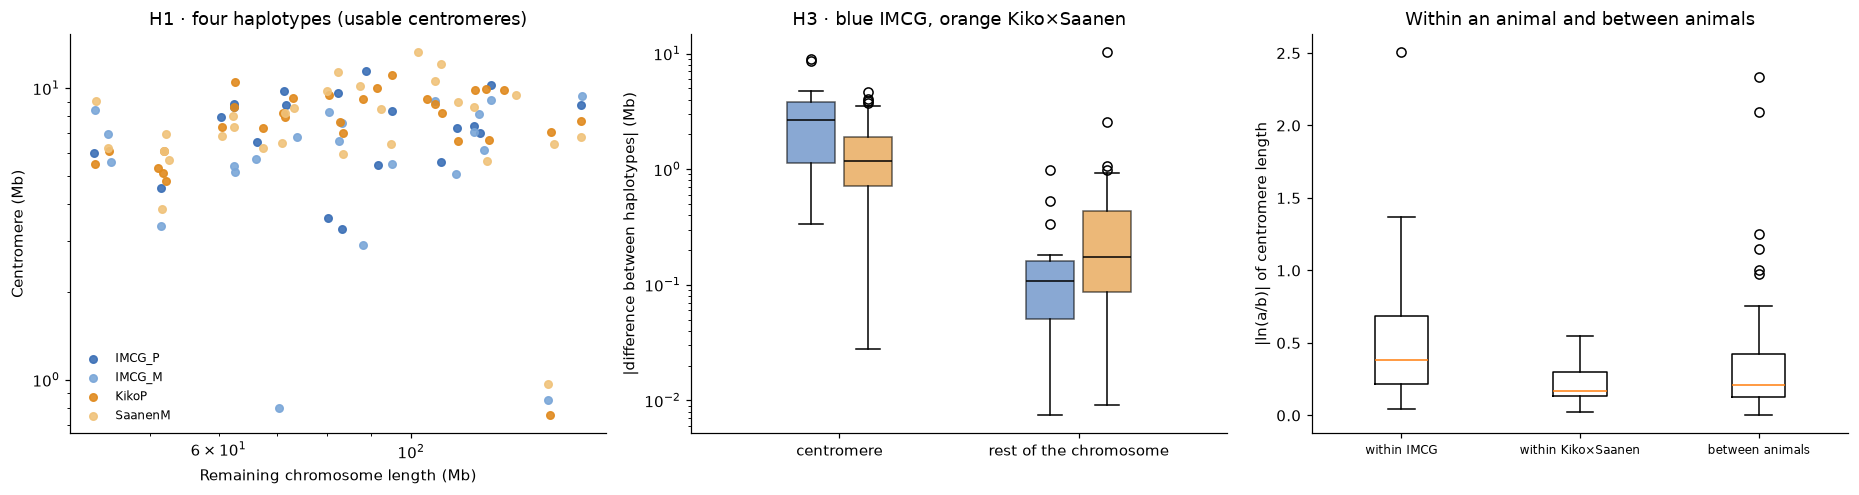

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for h in HAPS:
    g = U[U.hap == h]; ax[0].scatter(g.rest_Mb, g.cen_Mb, s=24, color=COL[h], label=h, alpha=.9)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('Remaining chromosome length (Mb)'); ax[0].set_ylabel('Centromere (Mb)'); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title('H1 · four haplotypes (usable centromeres)')
for a_, col, off in (('IMCG', '#3b6fb6', -.12), ('Kiko×Saanen', '#e08a1e', .12)):
    d = PP[PP.animal == a_]; ax[1].boxplot([d.abs_cen, d.abs_rest], positions=[1 + off, 2 + off], widths=.2, patch_artist=True, boxprops=dict(facecolor=col, alpha=.6), medianprops=dict(color='k'))
ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(['centromere', 'rest of the chromosome']); ax[1].set_yscale('log'); ax[1].set_ylabel('|difference between haplotypes| (Mb)')
ax[1].set_title('H3 · blue IMCG, orange Kiko×Saanen')
order = ['within IMCG', 'within Kiko×Saanen', 'between animals']
ax[2].boxplot([wb[wb.type == k].d for k in order], showfliers=True); ax[2].set_xticklabels(order, fontsize=8); ax[2].set_ylabel('|ln(a/b)| of centromere length'); ax[2].set_title('Within an animal and between animals')
plt.tight_layout(); plt.savefig(FIG/'two_animals.png', dpi=150); plt.show()

## 3.12 · Centromeres worth a second look
Usable centromeres whose satellite is more than twice or less than half of that of T2T-goat2.0, and chromosomes that were left out because of a gap. This is a list of cases, not a filter.

In [21]:
q = D[D.hap.isin(['KikoP', 'SaanenM'])].copy()
odd = q[(q.sat_vs_T2T > 2) | (q.sat_vs_T2T < 0.5) | (~q.complete) | q.low_satellite][['hap', 'chr', 'cen_len', 'sat_frac', 'n_gaps_cen', 'sat_vs_T2T', 'complete', 'low_satellite']]
odd['cen_len'] = (odd.cen_len/1e6).round(2); display(odd.round(2)); odd.to_csv(OUT/'cases_to_review.csv', index=False)

,hap,chr,cen_len,sat_frac,n_gaps_cen,sat_vs_T2T,complete,low_satellite
72,KikoP,CHI14,11.11,0.81,0,2.16,True,False
93,SaanenM,CHI5,14.97,0.65,1,2.46,False,False
95,SaanenM,CHI7,12.08,0.71,0,2.08,True,False
103,SaanenM,CHI15,11.39,0.60,0,2.16,True,False


## 3.13 · Things to keep in mind when reading these results
The four centromeres listed above were reviewed by hand. They stay in the analysis. This is what the review found, and it should be kept in mind when interpreting H1 and H3.

- Kiko CHI14, Saanen CHI7 and Saanen CHI15 have much more satellite than the same chromosome in the other haplotypes, mostly SatI. In all three the chromosome is longer by about the same amount as the centromere, so the extra sequence is in the assembly and is not a detection error. It could be a real expansion of the array or a duplication made by the assembler. Without long reads from the same animal the two cannot be told apart.
- In Saanen CHI15 the block is inflated by about 3 Mb of spacer between two small satellite islands that were merged. The satellite alone is 6.9 Mb, 2.2 times the value in T2T-goat2.0.
- Saanen CHI5 reaches 14.97 Mb, which is the size of the 15-Mb window, so its block is probably cut and the real centromere is longer. It also has a gap. It is left out as incomplete and does not enter H1 or H3.
- These three chromosomes carry the largest differences between KikoP and SaanenM, so the replication of H3 in the second animal depends on them. The cell below shows how much. Removing them only because their differences are large would be selecting against the hypothesis, so they are kept. The fair reading is that H3 replicates in part in the second animal, and that the replication rests on three chromosomes with large expansions of uncertain origin. Pooled over both animals it is clear either way.
- H1 does not depend on them.

In [22]:
# Sensitivity, for reference only. The results above are the ones that count.
three = ['CHI7', 'CHI14', 'CHI15']
sens = [test(PB, 'abs_cen', 'abs_rest', 'Kiko×Saanen, absolute (Mb), all pairs'),
        test(PB[~PB.chr.isin(three)], 'abs_cen', 'abs_rest', 'Kiko×Saanen, absolute (Mb), without CHI7, CHI14 and CHI15'),
        test(PP, 'abs_cen', 'abs_rest', 'Both animals, absolute (Mb), all pairs'),
        test(PP[~PP.chr.isin(three)], 'abs_cen', 'abs_rest', 'Both animals, absolute (Mb), without CHI7, CHI14 and CHI15')]
display(pd.DataFrame(sens).round(4))
drop = [('KikoP', 'CHI14'), ('SaanenM', 'CHI7'), ('SaanenM', 'CHI15')]
no3 = U[~U.apply(lambda r: (r.hap, r.chr) in drop, axis=1)]
sh1 = pd.DataFrame([fit(U[U.kind == 'autosome'], 'Four haplotypes, autosomes', cluster=True), fit(no3[no3.kind == 'autosome'], 'Four haplotypes, autosomes, without the three centromeres', cluster=True)])
sh1.to_csv(OUT/'sensitivity_three_centromeres.csv', index=False); display(sh1.round(3))

,comparison,n,median_centromere,median_rest,CI95_median_diff,p_permutation
0,"Kiko×Saanen, absolute (Mb), all pairs",28,1.1708,0.1751,"[0.531, 1.39]",0.0301
1,"Kiko×Saanen, absolute (Mb), without CHI7, CHI14 and CHI15",25,1.0762,0.1296,"[0.427, 1.2]",0.1684
2,"Both animals, absolute (Mb), all pairs",44,1.2829,0.1372,"[0.683, 1.94]",0.0001
3,"Both animals, absolute (Mb), without CHI7, CHI14 and CHI15",39,1.1747,0.1296,"[0.549, 1.53]",0.0005


,model,n,slope,CI95,CI95_boot,p_slope_0,R2
0,"Four haplotypes, autosomes",98,0.295,"[0.10, 0.49]","[0.12, 0.52]",0.002,0.081
1,"Four haplotypes, autosomes, without the three centromeres",95,0.278,"[0.09, 0.47]","[0.11, 0.49]",0.004,0.075


## 3.14 · Results summary and files

In [23]:
# Adds the numbers of the screening and of Part B to results_summary.json
sc = pd.read_csv(TAB/'screening'/'screen_summary.csv', index_col=0)
r1 = h1_two.set_index('model'); r3 = h3_two.set_index('comparison'); s3 = pd.DataFrame(sens).set_index('comparison')
extra = {
 'screening_assemblies': int(len(sc.drop(index='T2T (ref)'))),
 'screening_resolved_KikoP': int(sc.loc['KikoP', 'resolved']), 'screening_resolved_SaanenM': int(sc.loc['SaanenM', 'resolved']),
 'screening_resolved_best_other': int(sc.drop(index=['T2T (ref)', 'KikoP', 'SaanenM']).resolved.max()),
 'H1_two_animals_slope_autosomes_pooled': float(r1.loc['All four haplotypes, autosomes only', 'slope']), 'H1_two_animals_CI95_autosomes_pooled': r1.loc['All four haplotypes, autosomes only', 'CI95'],
 'H1_two_animals_slope_with_X_pooled': float(r1.loc['All four haplotypes', 'slope']), 'H1_two_animals_slope_difference_between_animals': float(mi.params[term]),
 'H3_second_animal_median_centromere_Mb': float(r3.loc['Kiko×Saanen (KikoP vs SaanenM), absolute (Mb)', 'median_centromere']), 'H3_second_animal_median_rest_Mb': float(r3.loc['Kiko×Saanen (KikoP vs SaanenM), absolute (Mb)', 'median_rest']),
 'H3_second_animal_p_permutation_absolute': float(r3.loc['Kiko×Saanen (KikoP vs SaanenM), absolute (Mb)', 'p_permutation']),
 'H3_second_animal_p_permutation_absolute_without_three_chromosomes': float(s3.loc['Kiko×Saanen, absolute (Mb), without CHI7, CHI14 and CHI15', 'p_permutation']),
 'H3_both_animals_pairs': int(r3.loc['Both animals pooled, absolute (Mb)', 'n']), 'H3_both_animals_p_permutation_absolute': float(r3.loc['Both animals pooled, absolute (Mb)', 'p_permutation']),
 'within_between_median_abs_ln_ratio': {k: round(float(v), 3) for k, v in wb.groupby('type').d.median().items()},
}
summary = json.loads((TAB/'results_summary.json').read_text()); summary.update(extra)
(TAB/'results_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False)); print(json.dumps(extra, indent=2, ensure_ascii=False))

{
  "screening_assemblies": 20,
  "screening_resolved_KikoP": 29,
  "screening_resolved_SaanenM": 27,
  "screening_resolved_best_other": 17,
  "H1_two_animals_slope_autosomes_pooled": 0.2947219826926801,
  "H1_two_animals_CI95_autosomes_pooled": "[0.10, 0.49]",
  "H1_two_animals_slope_with_X_pooled": 0.0020389997606929944,
  "H1_two_animals_slope_difference_between_animals": 7.744290183892e-05,
  "H3_second_animal_median_centromere_Mb": 1.17075,
  "H3_second_animal_median_rest_Mb": 0.17514849999999998,
  "H3_second_animal_p_permutation_absolute": 0.030139849300753495,
  "H3_second_animal_p_permutation_absolute_without_three_chromosomes": 0.16835415822920885,
  "H3_both_animals_pairs": 44,
  "H3_both_animals_p_permutation_absolute": 5.9999700001499995e-05,
  "within_between_median_abs_ln_ratio": {
    "between animals": 0.213,
    "within IMCG": 0.38,
    "within Kiko×Saanen": 0.166
  }
}


### Files written to `data/`
| File | Content |
|---|---|
| `H1_scaling.csv`, `H1_influence.csv`, `H1_interaction.csv`, `H1_power*.csv` | scaling in the reference animal: influence, P against M interaction, power |
| `H2_family_allometry.csv`, `H2_composition.csv`, `H2_influence.csv`, `H1H2_chromosome_table_T2T.csv` | satellite composition |
| `H3_homologs.csv`, `H3_summary.csv`, `H3_sensitivity.csv` | homologs P against M in the reference animal |
| `breeds_pacbio.csv` | variation between breeds (exploratory) |
| `two_animals/*.csv` | H1 and H3 in the four haplotypes, within and between animals, centromeres to review, sensitivity |
| `figures/*.png`, `results_summary.json` | figures and summary |